# Scam intent: dataset audit and TF-IDF baseline

First text-track milestone. Input: **dialogue only**. Target: `label` (1 scam, 0 benign).
`type` is retained for audit/evaluation and never enters the classifier.

Run in VS Code with a Colab A100 kernel, or in Google Colab. This notebook is
self-contained; there is no need to clone/upload source modules. Runtime checks
fail unless a Colab A100 is actually present. Scikit-learn itself fits on CPU;
the A100 is reserved for the upcoming frozen MiniLM experiment.

The original 1,280/320 split is preserved, with 192 validation rows selected only
from published training rows (label stratification, seed 42). All 1,600 assignments
remain in the manifest. Two duplicate training rows are excluded from fitting,
leaving **1,086 train / 192 validation / 320 test**. Non-exact template matches are
retained and reported as a limitation; this is not a template-disjoint benchmark.

**Test predictions and test metrics are deliberately deferred** until the MiniLM
comparison settings have been frozen. This notebook exports training OOF and
validation scores only. No test outcomes are used for model or threshold choice.

Sources: [dataset card](https://huggingface.co/datasets/BothBosu/scam-dialogue/blob/321b961b5ae353e19ed479b960658dcd223d5e06/README.md),
[MiniLM card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2).
These synthetic dialogues do not establish real-world scam-call reliability.


In [2]:
import os
from pathlib import Path
import subprocess
import sys

# Keep the default for the requested remote run. Set the environment variable to 0
# only for an explicitly labelled local smoke run.
REQUIRE_COLAB_A100 = os.environ.get("SCAM_REQUIRE_COLAB_A100", "1") == "1"
try:
    gpu = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], text=True
    ).strip()
except (OSError, subprocess.SubprocessError):
    gpu = "unavailable"
is_colab = bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
print({"Colab runtime": is_colab, "GPU": gpu, "Python": sys.version})
if REQUIRE_COLAB_A100:
    assert is_colab and "A100" in gpu, "Connect a Colab A100 kernel before running."


{'Colab runtime': True, 'GPU': 'NVIDIA A100-SXM4-40GB, 40960 MiB', 'Python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]'}


## Dependencies and paths

Pinned text-baseline dependencies are isolated from teammates' shared setup.
Installation happens before importing numerical libraries. If this kernel has
already imported another NumPy/pandas version, restart it before Run All.
Colab files are ephemeral: download the output archive at the end.


In [3]:
requirements = '# Isolated baseline/Colab environment. Shared pyproject.toml and uv.lock are unchanged.\nnumpy==2.2.6\npandas==2.3.3\nscipy==1.18.1\nscikit-learn==1.7.2\nmatplotlib==3.10.7\njoblib==1.6.0\nnbformat==5.10.4\nnbclient==0.10.2\nipykernel==7.0.1\n'
if is_colab:
    import importlib.metadata
    requested = [line for line in requirements.splitlines() if line and not line.startswith("#")]
    mismatches = []
    for item in requested:
        name, expected = item.split("==")
        try:
            actual = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            actual = None
        if actual != expected:
            mismatches.append(item)
    if mismatches:
        loaded_before_install = [name for name in ("numpy", "pandas", "scipy", "sklearn", "matplotlib") if name in sys.modules]
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *requested], check=True)
        if loaded_before_install:
            raise RuntimeError("Dependencies installed. Restart the kernel and Run All before importing numerical libraries.")

ROOT = Path.cwd()
if not is_colab:
    ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), ROOT)
DATA_DIR = ROOT / "data/scam_dialogue"
OUTPUT_DIR = ROOT / "outputs/text/baseline"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Artifacts:", OUTPUT_DIR)


Artifacts: /content/outputs/text/baseline


## Implementation and runtime provenance

Embedded from `src/text/baseline.py`; source SHA-256: `a31d5ab9d84b34315e4d5f96ed019fcb6ad846963259dad4c7af882eff50bd52`.
Regenerate using `python src/text/build_notebook.py` after code changes.


In [4]:
from __future__ import annotations

import argparse
import hashlib
import importlib.metadata
import json
import platform
import re
import subprocess
import sys
import unicodedata
from pathlib import Path
from urllib.request import urlopen

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.feature_extraction.text import HashingVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, confusion_matrix, f1_score,
    precision_score, recall_score,
)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.pipeline import Pipeline

REVISION = "321b961b5ae353e19ed479b960658dcd223d5e06"
DATASET = "BothBosu/scam-dialogue"
SOURCE_SHA256 = {
    "scam-dialogue_train.csv": "cda5d42d15fd341208a25466d9ea279de905a640bd153f67b5c29743520f96f8",
    "scam-dialogue_test.csv": "17a9e52e90d893541d76dbb4588cb75b1a66ef2474ef2619d56feff5b8d5aec0",
}
SEED = 42
NEAR_THRESHOLD = 0.90
TURN = re.compile(r"\b(?:caller|receiver)\s*:", re.IGNORECASE)


def sha256(value: str | bytes) -> str:
    return hashlib.sha256(value.encode("utf-8") if isinstance(value, str) else value).hexdigest()


def normalized(text: str) -> str:
    return " ".join(unicodedata.normalize("NFKC", text).casefold().split())


def turns(text: str) -> list[str]:
    starts = [m.start() for m in TURN.finditer(text)]
    if not starts:
        return [text]
    starts[0] = 0  # Preserve any preamble.
    return [text[a:b].strip() for a, b in zip(starts, starts[1:] + [len(text)])]


def prefix(text: str, fraction: float) -> str:
    items = turns(text)
    return " ".join(items[:max(1, int(np.ceil(len(items) * fraction)))])


def write_json(path: Path, value) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")


def runtime_info(require_a100: bool = False) -> dict:
    try:
        result = subprocess.run(
            ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
            capture_output=True, text=True, timeout=15, check=True,
        )
        gpu = result.stdout.strip()
    except (OSError, subprocess.SubprocessError):
        gpu = "unavailable"
    # This detects the remote runtime, including a VS Code Colab kernel.
    import os
    colab = bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
    info = {
        "python": sys.version, "platform": platform.platform(), "gpu": gpu,
        "colab_runtime": colab,
        "classifier_compute": "CPU (scikit-learn TF-IDF/logistic regression)",
        "versions": {name: importlib.metadata.version(name) for name in
                     ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "joblib"]},
    }
    if require_a100 and not (colab and "A100" in gpu):
        raise RuntimeError(f"A Colab A100 runtime is required; observed: {info}")
    return info

In [5]:
def load_data(data_dir: Path, output_dir: Path) -> pd.DataFrame:
    data_dir.mkdir(parents=True, exist_ok=True)
    frames, files = [], {}
    for source, count in [("train", 1280), ("test", 320)]:
        name = f"scam-dialogue_{source}.csv"
        # Cache names are revision-scoped so a different snapshot cannot be reused silently.
        path = data_dir / REVISION / name
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.exists():
            url = f"https://huggingface.co/datasets/{DATASET}/resolve/{REVISION}/{name}"
            with urlopen(url, timeout=120) as response:
                payload = response.read()
            path.write_bytes(payload)
        files[name] = sha256(path.read_bytes())
        if files[name] != SOURCE_SHA256[name]:
            raise ValueError(f"Dataset checksum mismatch: {path}; investigate cache/source before proceeding")
        frame = pd.read_csv(path, keep_default_na=False)
        if set(frame.columns) != {"dialogue", "type", "label"} or len(frame) != count:
            raise ValueError(f"Unexpected schema/count in {name}: {frame.shape}, {frame.columns}")
        if not frame.label.isin([0, 1]).all():
            raise ValueError("Labels must be 0/1")
        frame["source_split"] = source
        frame["source_row"] = np.arange(len(frame))  # zero-based CSV data-row ordinal
        frame["text_sha256"] = frame.dialogue.map(sha256)
        frame["normalized_sha256"] = frame.dialogue.map(lambda s: sha256(normalized(s)))
        frame["dialogue_id"] = [f"scam-{source}-{i:04d}-{digest[:16]}"
                                for i, digest in zip(frame.source_row, frame.text_sha256)]
        frame["split"] = source
        frames.append(frame)
    data = pd.concat(frames, ignore_index=True)
    train_indices = data.index[data.source_split.eq("train")]
    _, validation = train_test_split(
        train_indices, test_size=192, random_state=SEED,
        stratify=data.loc[train_indices, "label"],
    )
    data.loc[validation, "split"] = "validation"
    data["included"] = True
    data["exclusion_reason"] = ""
    empty = data.dialogue.str.strip().eq("")
    if empty[data.split.eq("test")].any():
        raise ValueError("Missing test text: preserve test and investigate before fitting")
    data.loc[empty, ["included", "exclusion_reason"]] = [False, "missing_text"]
    # Preserve test, then validation; remove exact/whitespace/case duplicates from lower-priority pools.
    # Similarity matches alone NEVER cause exclusions.
    priority = {"test": 0, "validation": 1, "train": 2}
    ordered = data.assign(priority=data.split.map(priority)).sort_values(["priority", "source_row"])
    for _, group in ordered.loc[~empty.reindex(ordered.index)].groupby("normalized_sha256", sort=False):
        if len(group) < 2:
            continue
        if group.label.nunique() != 1:
            raise ValueError("Conflicting labels in duplicate group; manual review required")
        keep = group.iloc[0]
        for index, row in group.iloc[1:].iterrows():
            if row.split != "test":
                data.loc[index, ["included", "exclusion_reason"]] = [
                    False, f"normalized_duplicate_of:{keep.dialogue_id}"]
    if not data.dialogue_id.is_unique:
        raise ValueError("ID collision")
    manifest_cols = ["dialogue_id", "source_split", "source_row", "text_sha256",
                     "normalized_sha256", "split", "label", "included", "exclusion_reason"]
    output_dir.mkdir(parents=True, exist_ok=True)
    manifest_text = data[manifest_cols].to_csv(index=False, lineterminator="\n")
    (output_dir / "split_manifest.csv").write_text(manifest_text, encoding="utf-8", newline="")
    write_json(output_dir / "dataset_provenance.json", {
        "dataset": DATASET, "revision": REVISION, "file_sha256": files,
        "seed": SEED, "validation_size": 192, "stratification": "label",
        "id_rule": "scam-{published_split}-{zero_based_row:04d}-{raw_text_sha256[:16]}",
    })
    return data

In [6]:
def audit(data: pd.DataFrame, output_dir: Path) -> dict:
    lengths = data[["dialogue_id", "split", "label", "type", "included"]].copy()
    lengths["characters"] = data.dialogue.str.len()
    lengths["words"] = data.dialogue.str.split().map(len)
    lengths["turns"] = data.dialogue.map(lambda s: len(turns(s)))
    lengths.to_csv(output_dir / "dialogue_lengths.csv", index=False)
    balance = data.groupby(["split", "included", "label", "type"]).size().rename("count").reset_index()
    balance.to_csv(output_dir / "class_type_counts.csv", index=False)
    duplicate_rows = data[data.duplicated("normalized_sha256", keep=False)]
    duplicate_rows.drop(columns="dialogue").to_csv(output_dir / "exact_duplicate_rows.csv", index=False)
    # Stateless character hashing is an audit instrument only, never a model input.
    hasher = HashingVectorizer(analyzer="char", ngram_range=(5, 5), n_features=2**18,
                               alternate_sign=False, lowercase=True, norm="l2")
    vectors = hasher.transform(data.dialogue.map(normalized))
    similarity = (vectors @ vectors.T).toarray()
    upper = np.triu(np.ones(similarity.shape, dtype=bool), 1)
    cross = data.split.to_numpy()[:, None] != data.split.to_numpy()[None, :]
    indices = np.argwhere(upper & cross & (similarity >= NEAR_THRESHOLD))
    records = []
    for i, j in indices:
        a, b = data.iloc[i], data.iloc[j]
        records.append({"id_a": a.dialogue_id, "id_b": b.dialogue_id,
                        "split_a": a.split, "split_b": b.split,
                        "similarity": float(similarity[i, j]),
                        "normalized_exact": a.normalized_sha256 == b.normalized_sha256,
                        "included_a": bool(a.included), "included_b": bool(b.included)})
    columns = ["id_a", "id_b", "split_a", "split_b", "similarity", "normalized_exact", "included_a", "included_b"]
    pairs = pd.DataFrame(records, columns=columns).sort_values("similarity", ascending=False)
    pairs.to_csv(output_dir / "near_duplicate_candidates.csv", index=False)
    # Keep full matching text locally for actual human inspection, including the most similar
    # pair for each split boundary even if no pair clears the candidate threshold.
    review = pairs.to_dict("records")
    for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
        a = data.index[data.split.eq(left)].to_numpy()
        b = data.index[data.split.eq(right)].to_numpy()
        local_i, local_j = np.unravel_index(np.argmax(similarity[np.ix_(a, b)]), (len(a), len(b)))
        i, j = a[local_i], b[local_j]
        review.append({"id_a": data.iloc[i].dialogue_id, "id_b": data.iloc[j].dialogue_id,
                       "similarity": float(similarity[i, j]), "boundary_maximum": f"{left}/{right}"})
    lookup = data.set_index("dialogue_id")
    for row in review:
        row["dialogue_a"] = lookup.loc[row["id_a"], "dialogue"]
        row["dialogue_b"] = lookup.loc[row["id_b"], "dialogue"]
    write_json(output_dir / "similarity_review_text.json", review)
    summary = {
        "raw_rows": len(data), "missing_text": int(data.dialogue.str.strip().eq("").sum()),
        "planned_counts": data.split.value_counts().to_dict(),
        "included_counts": data[data.included].split.value_counts().to_dict(),
        "excluded_count": int((~data.included).sum()),
        "raw_exact_duplicate_groups": int(data.groupby("text_sha256").size().gt(1).sum()),
        "normalized_duplicate_groups": int(data.groupby("normalized_sha256").size().gt(1).sum()),
        "cross_split_candidates": len(pairs), "candidate_threshold": NEAR_THRESHOLD,
        "audit_similarity": "cosine of stateless 2^18-bin character 5-gram hashes; collisions possible",
        "length_summary": lengths[["characters", "words", "turns"]].describe().to_dict(),
        "exclusion_policy": "Missing text and normalized exact duplicates only; test always retained. No similarity-only exclusions.",
        "wordpiece_lengths": "Deferred to the MiniLM milestone; word counts are not wordpiece counts.",
    }
    write_json(output_dir / "audit_summary.json", summary)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for split, group in lengths.groupby("split"):
        axes[0].hist(group.words, bins=25, histtype="step", label=split)
        axes[1].hist(group.turns, bins=20, histtype="step", label=split)
    axes[0].set(xlabel="Whitespace-separated words", ylabel="Dialogues")
    axes[1].set(xlabel="Speaker turns", ylabel="Dialogues")
    axes[0].legend()
    fig.tight_layout()
    fig.savefig(output_dir / "dialogue_lengths.png", dpi=160)
    plt.close(fig)
    return summary

In [7]:
def metrics(labels, scores, threshold: float) -> dict:
    labels, scores = np.asarray(labels), np.asarray(scores)
    predictions = scores >= threshold
    return {"n": len(labels), "scam_support": int(labels.sum()),
            "precision": float(precision_score(labels, predictions, zero_division=0)),
            "recall": float(recall_score(labels, predictions, zero_division=0)),
            "f1": float(f1_score(labels, predictions, zero_division=0)),
            "accuracy": float(np.mean(labels == predictions)),
            "false_positive_rate": float(np.mean(predictions[labels == 0])) if np.any(labels == 0) else None,
            "confusion_matrix": confusion_matrix(labels, predictions, labels=[0, 1]).tolist()}

In [8]:
def train_baseline(data: pd.DataFrame, output_dir: Path) -> tuple[Pipeline, dict]:
    train = data[data.included & data.split.eq("train")].copy()
    validation = data[data.included & data.split.eq("validation")].copy()
    candidates, fitted = [], []
    for ngram in [(1, 1), (1, 2)]:
        for c in [0.1, 1.0, 10.0]:
            model = Pipeline([
                ("tfidf", TfidfVectorizer(ngram_range=ngram, min_df=2, sublinear_tf=True)),
                ("classifier", LogisticRegression(C=c, max_iter=2000, solver="liblinear", random_state=SEED)),
            ])
            # dialogue is the ONLY feature; no type, ID, split, or target enters the pipeline.
            model.fit(train.dialogue, train.label)
            score = model.predict_proba(validation.dialogue)[:, 1]
            result = {"ngram_max": ngram[1], "C": c, **metrics(validation.label, score, 0.5)}
            candidates.append(result)
            fitted.append((model, score))
    table = pd.DataFrame(candidates).drop(columns="confusion_matrix")
    table.to_csv(output_dir / "validation_search.csv", index=False)
    # Deterministic ties: simpler ngrams, then stronger regularization (loop order).
    best = max(range(len(candidates)), key=lambda i: candidates[i]["f1"])
    model, scores = fitted[best]
    thresholds = sorted(set([0.5, 0.0, 1.0, *map(float, scores)]))
    threshold = max(thresholds, key=lambda t: (
        f1_score(validation.label, scores >= t, zero_division=0), -abs(t - 0.5), t))
    result = {"model": "tfidf_logreg", "seed": SEED,
              "ngram_range": [1, candidates[best]["ngram_max"]], "C": candidates[best]["C"],
              "threshold": threshold, "threshold_rule": "score >= threshold",
              "selection": "validation F1 at 0.5, ties simplest ngrams then smallest C; threshold then maximizes validation F1 with ties closest to 0.5",
              "fit_n": len(train), "validation_at_0_5": metrics(validation.label, scores, 0.5),
              "validation": metrics(validation.label, scores, threshold),
              "test_evaluated": False, "dataset_revision": REVISION}
    model_path = output_dir / "tfidf_logreg.joblib"
    joblib.dump({"pipeline": model, "config": result}, model_path)
    result["saved_model_sha256"] = sha256(model_path.read_bytes())
    write_json(output_dir / "frozen_config.json", result)
    validation = validation.assign(scam_score=scores, prediction=(scores >= threshold).astype(int))
    validation.drop(columns="dialogue").to_csv(output_dir / "validation_predictions.csv", index=False)
    by_type = []
    for kind, group in validation.groupby("type"):
        # Types are single-class; precision/F1 are undefined for benign-only groups.
        row = {"type": kind, **metrics(group.label, group.scam_score, threshold)}
        if row["scam_support"] == 0:
            row.update(precision=None, recall=None, f1=None)
        by_type.append(row)
    pd.DataFrame(by_type).drop(columns="confusion_matrix").to_csv(output_dir / "validation_by_type.csv", index=False)
    errors = validation[validation.label.ne(validation.prediction)].copy()
    errors["error_kind"] = np.where(errors.label.eq(0), "false_positive", "false_negative")
    errors.to_csv(output_dir / "validation_errors.csv", index=False)
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(validation.label, validation.prediction,
        labels=[0, 1], display_labels=["Benign", "Scam"], ax=ax, colorbar=False)
    ax.set_title(f"Validation, threshold={threshold:.3f}")
    fig.tight_layout()
    fig.savefig(output_dir / "validation_confusion_matrix.png", dpi=160)
    plt.close(fig)
    return model, result

In [9]:
def export_oof(data: pd.DataFrame, model: Pipeline, output_dir: Path) -> pd.DataFrame:
    """Fixed selected settings; refit vocabulary, IDF, classifier inside each fold."""
    train = data[data.included & data.split.eq("train")].copy().reset_index(drop=True)
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    train["fold"] = -1
    train["scam_score"] = np.nan
    for fold, (fit, heldout) in enumerate(splitter.split(train.dialogue, train.label, train.normalized_sha256)):
        assert set(train.iloc[fit].normalized_sha256).isdisjoint(train.iloc[heldout].normalized_sha256)
        fold_model = clone(model).fit(train.iloc[fit].dialogue, train.iloc[fit].label)
        train.loc[heldout, "scam_score"] = fold_model.predict_proba(train.iloc[heldout].dialogue)[:, 1]
        train.loc[heldout, "fold"] = fold
    validation = data[data.included & data.split.eq("validation")].copy()
    validation["fold"] = -1  # -1 means classifier fitted on the complete eligible training partition
    validation["scam_score"] = model.predict_proba(validation.dialogue)[:, 1]
    scores = pd.concat([train, validation], ignore_index=True).assign(model="tfidf_logreg")
    scores = scores[["dialogue_id", "split", "label", "model", "scam_score", "fold"]]
    assert scores.dialogue_id.is_unique and scores.scam_score.between(0, 1).all()
    scores.to_csv(output_dir / "fusion_scores_train_validation.csv", index=False)
    train[["dialogue_id", "fold"]].to_csv(output_dir / "oof_folds.csv", index=False)
    return scores


def score_transcripts(bundle_path: str | Path, transcripts: list[str]) -> np.ndarray:
    """Return uncalibrated scam-intent ranking scores; load only trusted joblib files."""
    bundle = joblib.load(bundle_path)
    return bundle["pipeline"].predict_proba(transcripts)[:, 1]

In [10]:
runtime = runtime_info(require_a100=REQUIRE_COLAB_A100)
write_json(OUTPUT_DIR / "runtime.json", runtime)
display(runtime)


{'python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]',
 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39',
 'gpu': 'NVIDIA A100-SXM4-40GB, 40960 MiB',
 'colab_runtime': True,
 'classifier_compute': 'CPU (scikit-learn TF-IDF/logistic regression)',
 'versions': {'numpy': '2.2.6',
  'pandas': '2.3.3',
  'scipy': '1.18.1',
  'scikit-learn': '1.7.2',
  'matplotlib': '3.10.7',
  'joblib': '1.6.0'}}

## Load, fix splits, and audit

Source files and raw text hashes are verified against a pinned Hugging Face commit.
IDs include the original file split, zero-based row, and raw-text hash. Exclusions
retain their original ID and assignment. Exact duplicates prioritize test, then
validation, then training; no test rows are removed. No similarity-only exclusions.

Near-match search uses stateless character 5-gram hashing and cosine similarity
(threshold 0.90). This is audit-only and learns no vocabulary/IDF from held-out data.
Every candidate's full text is saved for review; high similarity is a flag, not
proof of a repeated source example. Word lengths below are not wordpiece lengths.


{'raw_rows': 1600,
 'missing_text': 0,
 'planned_counts': {'train': 1088, 'test': 320, 'validation': 192},
 'included_counts': {'train': 1086, 'test': 320, 'validation': 192},
 'excluded_count': 2,
 'raw_exact_duplicate_groups': 2,
 'normalized_duplicate_groups': 2,
 'cross_split_candidates': 56,
 'candidate_threshold': 0.9,
 'audit_similarity': 'cosine of stateless 2^18-bin character 5-gram hashes; collisions possible',
 'length_summary': {'characters': {'count': 1600.0,
   'mean': 1402.66375,
   'std': 517.1546396018566,
   'min': 304.0,
   '25%': 1076.75,
   '50%': 1443.5,
   '75%': 1803.25,
   'max': 2382.0},
  'words': {'count': 1600.0,
   'mean': 243.51875,
   'std': 89.46898253143091,
   'min': 55.0,
   '25%': 188.0,
   '50%': 250.0,
   '75%': 312.25,
   'max': 413.0},
  'turns': {'count': 1600.0,
   'mean': 13.685625,
   'std': 4.351278763326146,
   'min': 6.0,
   '25%': 10.0,
   '50%': 13.0,
   '75%': 17.0,
   'max': 28.0}},
 'exclusion_policy': 'Missing text and normalized ex

,split,included,label,type,count
0,test,True,0,delivery,40
1,test,True,0,insurance,40
2,test,True,0,telemarketing,40
3,test,True,0,wrong,40
4,test,True,1,refund,40
5,test,True,1,reward,40
6,test,True,1,ssn,40
7,test,True,1,support,40
8,train,False,0,wrong,1
9,train,False,1,reward,1


,dialogue_id,split,label,exclusion_reason
614,scam-train-0614-2ba5858a6a871fcc,train,1,normalized_duplicate_of:scam-test-0125-2ba5858...
1143,scam-train-1143-42298682e83aee87,train,0,normalized_duplicate_of:scam-train-1138-422986...


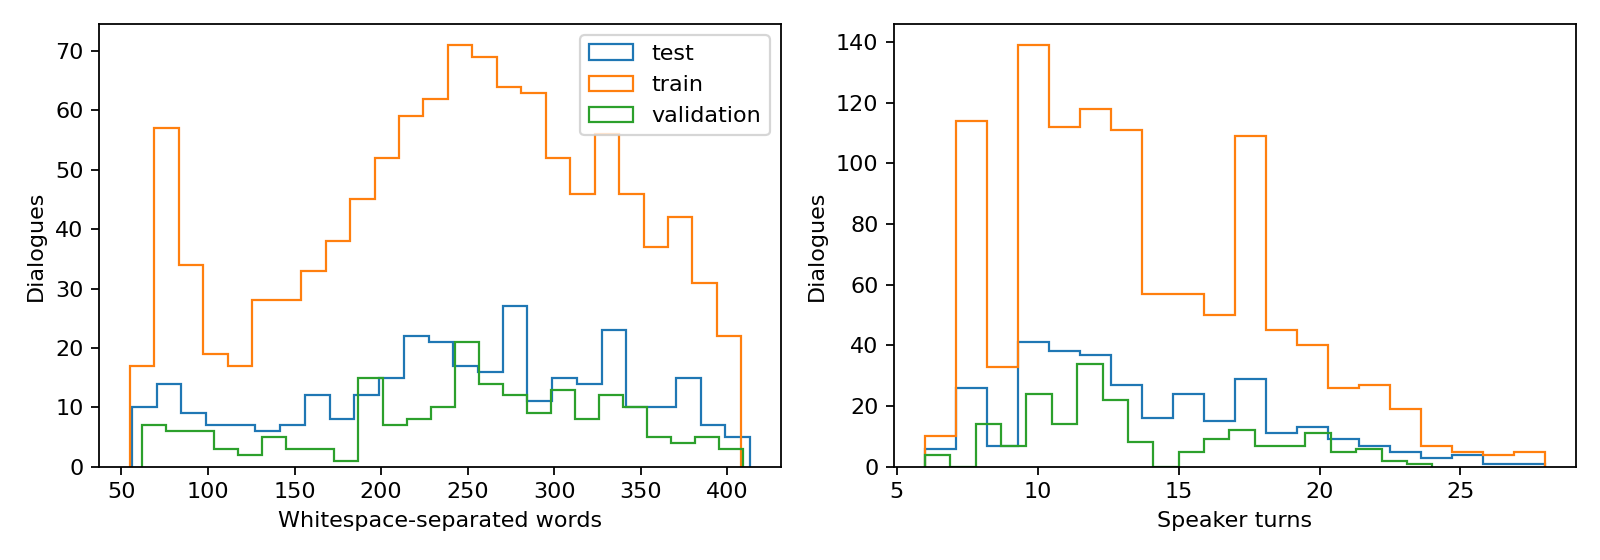

In [11]:
data = load_data(DATA_DIR, OUTPUT_DIR)
summary = audit(data, OUTPUT_DIR)
display(summary)
display(pd.read_csv(OUTPUT_DIR / "class_type_counts.csv"))
display(data.loc[~data.included, ["dialogue_id", "split", "label", "exclusion_reason"]])
from IPython.display import Image, display
display(Image(filename=str(OUTPUT_DIR / "dialogue_lengths.png")))


In [12]:
candidates = pd.read_csv(OUTPUT_DIR / "near_duplicate_candidates.csv")
display(candidates)
# The full dialogue pairs are available in similarity_review_text.json.
print("All candidate pairs:", len(candidates))
print("Human review conclusions are in notebooks/text/RESULTS.md and similarity_review.csv.")


,id_a,id_b,split_a,split_b,similarity,normalized_exact,included_a,included_b
0,scam-train-0614-2ba5858a6a871fcc,scam-test-0125-2ba5858a6a871fcc,train,test,1.000000,True,False,True
1,scam-train-1138-42298682e83aee87,scam-train-1143-42298682e83aee87,validation,train,1.000000,True,True,False
2,scam-train-1164-e900d6de1e51931a,scam-test-0318-96271b84d833a1b3,train,test,0.984476,False,True,True
3,scam-train-1138-42298682e83aee87,scam-train-1183-8b09a1dfb39581b7,validation,train,0.971229,False,True,True
4,scam-train-1138-42298682e83aee87,scam-train-1193-2c4529f17c450434,validation,train,0.963518,False,True,True
5,scam-train-1138-42298682e83aee87,scam-train-1197-52878a22c6558538,validation,train,0.963476,False,True,True
6,scam-train-1185-c4ac611a5cd790e7,scam-train-1200-77840459f9742a4f,train,validation,0.963357,False,True,True
7,scam-train-1138-42298682e83aee87,scam-train-1167-70273a208309bf3c,validation,train,0.957414,False,True,True
8,scam-train-1138-42298682e83aee87,scam-train-1171-c4c3cbd1793a820e,validation,train,0.955136,False,True,True
9,scam-train-1132-50e697894b176209,scam-train-1237-a8f2c55bceca33a6,validation,train,0.953368,False,True,True


All candidate pairs: 56
Human review conclusions are in notebooks/text/RESULTS.md and similarity_review.csv.


## Train and select using validation F1

Six settings: word unigrams or unigrams+bigrams, C in {0.1, 1, 10}, min_df=2,
sublinear term frequency. Each full Pipeline fits vocabulary, IDF, and logistic
regression on eligible training rows only. First choose settings by validation F1
at 0.5 (ties: unigrams, then smaller C), then choose the threshold by validation F1
(ties closest to 0.5). Save the training-fitted Pipeline and frozen configuration.


,ngram_max,C,n,scam_support,precision,recall,f1,accuracy,false_positive_rate
0,1,0.1,192,96,1.0,1.0,1.0,1.0,0.0
1,1,1.0,192,96,1.0,1.0,1.0,1.0,0.0
2,1,10.0,192,96,1.0,1.0,1.0,1.0,0.0
3,2,0.1,192,96,1.0,1.0,1.0,1.0,0.0
4,2,1.0,192,96,1.0,1.0,1.0,1.0,0.0
5,2,10.0,192,96,1.0,1.0,1.0,1.0,0.0


{'model': 'tfidf_logreg',
 'seed': 42,
 'ngram_range': [1, 1],
 'C': 0.1,
 'threshold': 0.5,
 'threshold_rule': 'score >= threshold',
 'selection': 'validation F1 at 0.5, ties simplest ngrams then smallest C; threshold then maximizes validation F1 with ties closest to 0.5',
 'fit_n': 1086,
 'validation_at_0_5': {'n': 192,
  'scam_support': 96,
  'precision': 1.0,
  'recall': 1.0,
  'f1': 1.0,
  'accuracy': 1.0,
  'false_positive_rate': 0.0,
  'confusion_matrix': [[96, 0], [0, 96]]},
 'validation': {'n': 192,
  'scam_support': 96,
  'precision': 1.0,
  'recall': 1.0,
  'f1': 1.0,
  'accuracy': 1.0,
  'false_positive_rate': 0.0,
  'confusion_matrix': [[96, 0], [0, 96]]},
 'test_evaluated': False,
 'dataset_revision': '321b961b5ae353e19ed479b960658dcd223d5e06',
 'saved_model_sha256': '8099a48debb8ea4859910671f46b0913c9bdbe116712b714606a202a70fae32a'}

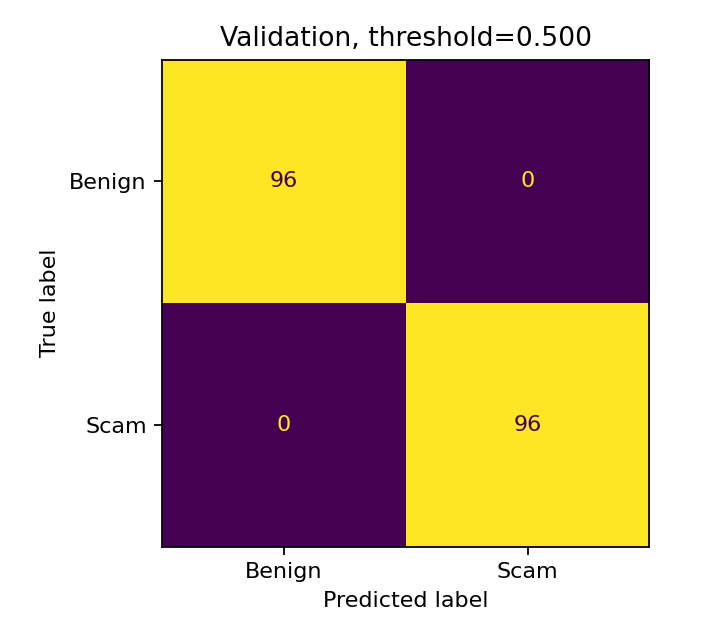

,type,n,scam_support,precision,recall,f1,accuracy,false_positive_rate
0,delivery,24,0,NaN,NaN,NaN,1.0,0.0
1,insurance,23,0,NaN,NaN,NaN,1.0,0.0
2,refund,21,21,1.0,1.0,1.0,1.0,NaN
3,reward,19,19,1.0,1.0,1.0,1.0,NaN
4,ssn,30,30,1.0,1.0,1.0,1.0,NaN
5,support,26,26,1.0,1.0,1.0,1.0,NaN
6,telemarketing,28,0,NaN,NaN,NaN,1.0,0.0
7,wrong,21,0,NaN,NaN,NaN,1.0,0.0


No validation false positives or false negatives; no error examples to interpret.


In [13]:
model, config = train_baseline(data, OUTPUT_DIR)
display(pd.read_csv(OUTPUT_DIR / "validation_search.csv"))
display(config)
display(Image(filename=str(OUTPUT_DIR / "validation_confusion_matrix.png")))
display(pd.read_csv(OUTPUT_DIR / "validation_by_type.csv"))
errors = pd.read_csv(OUTPUT_DIR / "validation_errors.csv")
if errors.empty:
    print("No validation false positives or false negatives; no error examples to interpret.")
else:
    display(errors[["dialogue_id", "type", "label", "scam_score", "error_kind", "dialogue"]])


## Fusion handoff: OOF training scores and validation scores

Five stratified group folds (seed 42, group=normalized text hash). For each held-out
fold, refit the full Pipeline on the other four folds. OOF uses the settings selected
on validation; it is fusion input, not an independent estimate of tuned-model quality.
Each included training dialogue is scored once by a classifier that did not fit it.
Excluded rows are absent. Validation uses the classifier fitted on all eligible
training rows. Folds are 0–4 for training, -1 for validation. Similar template variants
can still cross folds. Join through `dialogue_id`, never by row order.


In [14]:
scores = export_oof(data, model, OUTPUT_DIR)
display(scores.groupby(["split", "fold"]).agg(n=("dialogue_id", "size")))
display(scores.head())
assert len(scores) == int((data.included & data.split.ne("test")).sum())
assert len(data[data.split.eq("test")]) == 320
assert len(data[data.split.eq("test") & data.included]) == 320
assert not set(data.loc[data.included & data.split.eq("train"), "normalized_sha256"]) & set(
    data.loc[data.included & data.split.ne("train"), "normalized_sha256"])

# Confirm that the serialized preprocessing/classifier reproduces validation scores.
validation = data[data.included & data.split.eq("validation")]
restored = score_transcripts(OUTPUT_DIR / "tfidf_logreg.joblib", validation.dialogue.tolist())
np.testing.assert_allclose(restored, model.predict_proba(validation.dialogue)[:, 1])
print("Verified: split membership, OOF coverage, exact-duplicate separation, model round trip.")


n
split      fold     
train       0    218
            1    217
            2    217
            3    217
            4    217
validation -1    192

,dialogue_id,split,label,model,scam_score,fold
0,scam-train-0001-aa76d0a115a4235b,train,1,tfidf_logreg,0.715036,3
1,scam-train-0002-32f219b36252a557,train,1,tfidf_logreg,0.734157,2
2,scam-train-0003-015c37dc75f3d83d,train,1,tfidf_logreg,0.742987,2
3,scam-train-0005-6bab3fd6d1d317f7,train,1,tfidf_logreg,0.797643,4
4,scam-train-0006-601391f088083bf2,train,1,tfidf_logreg,0.765233,0


Verified: split membership, OOF coverage, exact-duplicate separation, model round trip.


## Interpretation and next milestone

Scam precision/recall/F1 use label 1 as positive. In benign-only types, report
false-positive rate and accuracy; scam recall/F1 are undefined. The validation set
is used for tuning, so its result is not an unbiased final estimate. Scores are
uncalibrated rankings, not real-world fraud probabilities. F1 >0.85 is exploratory.

Next: measure actual MiniLM wordpieces; split beyond 254 content tokens (reserve
special tokens within 256), embed chunks with the frozen encoder, average and cache
dialogue vectors, then fit/select logistic regression. Freeze both branches before
one final test evaluation. Then export test scores and frozen 25/50/75/100% turn
prefix scores. Early prefixes may end before a scam request appears.


In [15]:
# Retrieve this archive with the Colab CLI or the notebook Files panel.
import shutil
assert (OUTPUT_DIR / "frozen_config.json").exists(), "Training must complete before export."
assert (OUTPUT_DIR / "fusion_scores_train_validation.csv").exists(), "OOF export must complete before archiving."
archive = shutil.make_archive(str(ROOT / "text_baseline_artifacts"), "zip", OUTPUT_DIR)
print("Artifact archive:", archive)


Artifact archive: /content/text_baseline_artifacts.zip
